In [1]:
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
})

## Phantom parameters
Outer boundary: unit disc with radius of $r_{out} = 165$ mm, rod radius $ r = 0.05 r_{out} = 8.25$ mm, perturbed rod at origin, second rod at $(r, 3r)$.

Realistic linear attenuation values of water and uranium. Emission set to 100 (no unit).

In [2]:
r_out = 165.                   # Domain radius (mm)
r = 0.05 * r_out               # Rod radius (mm)
att_0, att_p, em_p = 0.0085, 0.14, 100. # Moderator attenuation, rod attenuation (1/mm), rod emission

# Rod B_p (the perturbed one) at the origin. The vertical line x = r is tangent to it.
c_p = (0., 0.)
# Second rod B_q further along on the tangent ray
c_q = (r, 3*r)

# Detector x(psi) on the boundary, on the tangent ray, below the rods
psi = np.arctan2(-np.sqrt(r_out**2 - r**2), r)
x_det = r_out * np.array([np.cos(psi), np.sin(psi)])
print(f"Rod radius r = {r:.2f} mm, detector x(psi) = ({x_det[0]:.2f}, {x_det[1]:.2f}) mm, psi = {np.rad2deg(psi):.3f} deg")

Rod radius r = 8.25 mm, detector x(psi) = (8.25, -164.79) mm, psi = -87.134 deg


## Analytic forward model

Given detector position $x(\psi)$ at the outer boundary and ray direction $\theta(\omega)$, we need to compute the chord length for any rod $B_p$.

In [3]:
def chord(x, omega, center, radius):
    r'''Compute entry and exit parameters s_- <= s_+ (clipped to s >= 0) of the backward ray x - s theta(omega)
    through the disc B(center, radius). Both are 0 if the ray misses the disc. Can accept vector of omegas.'''
    d = -np.stack([np.cos(omega), np.sin(omega)], axis=-1) # Backward direction -theta
    v = np.asarray(x, float) - np.asarray(center, float) # Detector location wrt. rod center
    B = d @ v # Projection of v to the ray, |B| is the (projected) distance to the rod center along the ray
    # Ray meets rod boundary when |v + s*d|^2 = r^2. Solving for s, the discriminant is
    disc = 4*(B**2 - (v @ v - radius**2))
    sq = np.sqrt(np.maximum(disc, 0.))
    hit = disc > 0 # disc = 0 means tangential ray but the chord length is still 0
    # Quadratic solution is (-2B +- sq) / 2 = -B +- 0.5sq
    s_in = np.where(hit, np.maximum(-B - 0.5*sq, 0.), 0.)
    s_out = np.where(hit, np.maximum(-B + 0.5*sq, 0.), 0.)
    return s_in, s_out

def attenuation_to(x, omega, s, rods, a0, skip=()):
    r'''int_0^s a(x - sigma theta(omega)) d sigma for the disc phantom (rods with index in `skip` removed).'''
    s_in, s_out = chord(x, omega, (0., 0.), r_out)
    A = a0 * np.clip(s - s_in, 0., s_out - s_in) # Beam transform through whole domain
    for q, (c, rq, fq, aq) in enumerate(rods):
        if q in skip:
            continue
        i, o = chord(x, omega, c, rq)
        A = A + (aq - a0) * np.clip(s - i, 0., o - i) # Add the extra attenuation
    return A

def transport(x, omega, rods, a0, skip=()):
    r'''Transport solution u(x, theta(omega)) of (2.3), i.e. the backward-ray integral from x.
    For x = x(psi) on the boundary this is the data R_a f(x(psi), theta(omega)).
    rods = [(center, radius, f, a), ...].
    Each rod contributes f/a (1 - e^{-a l}) e^{-A(s_-)}.'''
    omega = np.atleast_1d(np.asarray(omega, float))
    u = np.zeros_like(omega)
    for q, (c, rq, fq, aq) in enumerate(rods):
        if q in skip:
            continue
        s_in, s_out = chord(x, omega, c, rq)
        Da = attenuation_to(x, omega, s_in, rods, a0, skip) # Beam transform through rods
        u += (fq / aq) * np.exp(-Da) * (-np.expm1(-aq * (s_out - s_in)))
    return u

## Tangency, singular side and true values

In [4]:
def tangencies(x, center, radius):
    r'''Compute ray directions omega_0 for which the line through x is tangent to rod B(center, radius).
    Returns  list of parameters [(omega_0, eps_tau, L_tau, y_tau), ...].
    Angle beta is the backward direction and alpha is the direction of center - x, ray is
    tangent when beta = alpha -+ arcsin(r/b), and the ray enters the rod when beta moves towards alpha.'''
    v = np.asarray(center, float) - np.asarray(x, float)
    b = np.hypot(*v)
    alpha = np.arctan2(v[1], v[0])
    L = np.sqrt(b**2 - radius**2)
    out = []
    for sgn in (-1., +1.):
        beta = alpha + sgn*np.arcsin(radius / b)
        omega0 = (beta - np.pi + np.pi) % (2*np.pi) - np.pi # Values between -pi, pi
        eps = -sgn # beta towards alpha
        y = np.asarray(x) + L*np.array([np.cos(beta), np.sin(beta)])
        out.append((omega0, eps, L, y))
    return out

def closest_tangency(x, center, radius, omega):
    r'''Tangency of B(center, radius) seen from x whose direction is closest to omega.'''
    return min(tangencies(x, center, radius), key=lambda t: abs(np.angle(np.exp(1j*(t[0] - omega)))))

def check_simple(x, omega0, rods, p):
    r'''Distance from the other rod centers to the tangent line minus r.'''
    theta = np.array([np.cos(omega0), np.sin(omega0)])
    perp = np.array([-theta[1], theta[0]])
    for q, (c, rq, _, _) in enumerate(rods):
        if q != p:
            dist = abs(perp @ (np.asarray(c) - x)) - rq
            print(f"Rod {q} at {c}: |rho_q| - r = {dist:+.3f} mm")

def theory_phis(x, omega0, L, y, rods, a0, pairs, p=0):
    r'''Theoretical values for H = R_{a_1} f_1 - R_{a_2} f_2, where the phantoms differ only in rod p.
    `rods` is dataset 1, pairs = {name: (f2, a2)} have the values at rod p for dataset 2.
    Ray is tangent to rod p so all datasets are identical there.'''
    u = transport(y, omega0, rods, a0, skip=(p,))[0]
    Da = attenuation_to(x, np.atleast_1d(omega0), L, rods, a0, skip=(p,))[0]
    expDa = np.exp(-Da)
    k = np.sqrt(2 * rods[p][1] * L)
    (_, _, f1, a1) = rods[p]
    phiD1 = k * (f1 - (a1 - a0) * u) * expDa
    out = {}
    for name, (f2, a2) in pairs.items():
        phiD2 = k * (f2 - (a2 - a0) * u) * expDa
        phiDiff = k * ((a1 - a0) * phiD1 - (a2 - a0) * phiD2)
        out[name] = (phiD1 - phiD2, phiDiff)
    print(f"L = {L:.2f} mm: Da = {Da:.4f}, e^(-Da) = {expDa:.4e}, tangential trace u = {u:.4f}")
    print(f"F_p = f_p - (a_p - a_0) u = {f1 - (a1 - a0)*u:.4f}")
    return out, u, Da

## Finite difference estimates (5.1)–(5.2)

With $\gamma^2 = |\omega - \omega_0|$, $\varphi_\pm(\gamma) = H(\omega_0 \pm \epsilon_\tau\gamma^2)$ and fixed step $h$:

$$\Phi_D \approx \frac{1}{2} \frac{\varphi_+(\gamma+h) - \varphi_+(\gamma)}{h}, \qquad \Phi_N \approx -\left( \frac{1}{4} \frac{\varphi_+(\gamma+h) - 2\varphi_+(\gamma) + \varphi_+(\gamma-h)}{h^2} + \frac{1}{4\gamma}\frac{\varphi_-(\gamma+h) - \varphi_-(\gamma)}{h} \right).$$

On the non-intersecting side ($\Delta\omega < 0$ below) the $\Phi_D$ estimate uses $\varphi_-$ instead, which should tend to zero.

In [5]:
def fd_estimates(Hfun, omega0, eps, dOmegas, h=1e-4):
    r'''Phi_D and Phi_N estimates of H = Hfun(omega) at signed offsets dOmegas (positive = singular side).
    `h` is the step in gamma.
    PhiN is NaN on the non-intersecting side to keep same output length.'''
    dOmegas = np.asarray(dOmegas, float)
    sgn = np.where(dOmegas >= 0, 1., -1.)
    gamma = np.sqrt(np.abs(dOmegas))
    phi = lambda g, side: Hfun(omega0 + side * eps * sgn * g**2) # `side` gives phi_+ and phi_-
    PhiD = 0.5 * (phi(gamma + h, 1) - phi(gamma, 1)) / h
    centDif = -0.25 * (phi(gamma + h, 1) - 2*phi(gamma, 1) + phi(gamma - h, 1)) / h**2
    fwdDif = -(phi(gamma + h, -1) - phi(gamma, -1)) / (4 * gamma * h)
    PhiN = centDif + fwdDif
    PhiN[dOmegas < 0] = np.nan
    return PhiD, PhiN

def data_fun(rods, a0):
    return lambda om: transport(x_det, om, rods, a0)

## Comparison pairs
Dataset 1 is the reference phantom; dataset 2 changes only rod $B_p$ (same three perturbations as before).

In [6]:
e1, a2 = 0.8, 1.5 # Perturbed emission and attenuation values
comparisons = {
    "data1": {"fm2": e1*em_p, "am2": att_p,    "color": "C0", "label": rf"$\tilde f_p = {e1:1.1f} f_p$"},
    "data2": {"fm2": em_p,    "am2": a2*att_p, "color": "C1", "label": rf"$\tilde a_p = {a2:1.1f} a_p$"},
    "data3": {"fm2": e1*em_p, "am2": a2*att_p, "color": "C2", "label": rf"$\tilde f_p = {e1:1.1f} f_p$, $\tilde a_p = {a2:1.1f} a_p$"},
}
supnorms = {name: abs(em_p - c["fm2"]) + abs(att_p - c["am2"]) for name, c in comparisons.items()}

def perturbed(rods, comp, p=0):
    rods2 = list(rods)
    c, rq, _, _ = rods2[p]
    rods2[p] = (c, rq, comp["fm2"], comp["am2"])
    return rods2

In [7]:
def run_case(rods, omega0, eps, dOmegas, h):
    results = {}
    H1 = data_fun(rods, att_0)
    for name, comp in comparisons.items():
        H2 = data_fun(perturbed(rods, comp), att_0)
        PhiD, PhiN = fd_estimates(lambda om: H1(om) - H2(om), omega0, eps, dOmegas, h=h)
        results[name] = {"PhiD": PhiD, "PhiN": PhiN}
    return results

## Plotting

In [8]:
def plot_setup(rods, omega0, y, title=""):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.add_patch(Circle((0, 0), r_out, fc="0.9", ec="0.5", ls="--"))
    for q, (c, rq, fq, aq) in enumerate(rods):
        ax.add_patch(Circle(c, rq, fc="C0" if q == 0 else "C8", ec="k", alpha=0.8))
        ax.text(*c, r"$B_p$" if q == 0 else rf"$B_{q}$", ha="center", va="center")
    th = np.array([np.cos(omega0), np.sin(omega0)])
    far = chord(x_det, np.atleast_1d(omega0), (0, 0), r_out)[1][0]
    seg = np.stack([x_det, x_det - far*th])
    ax.plot(seg[:, 0], seg[:, 1], "r-", lw=1.2, label=r"tangent ray $L(\psi, \omega_0)$")
    ax.annotate("", xy=x_det, xytext=x_det - 30*th, arrowprops=dict(arrowstyle="->", color="r"))
    ax.scatter(*x_det, marker="*", s=150, c="r", zorder=5, label=r"detector $x(\psi)$")
    ax.scatter(*y, s=20, c="k", zorder=5, label=r"$y_\tau$")
    ax.set_xlim(-1.05*r_out, 1.05*r_out); ax.set_ylim(-1.05*r_out, 1.05*r_out)
    ax.set_aspect("equal"); ax.set_xlabel("mm"); ax.legend(loc="upper left", fontsize=8)
    ax.set_title(title)
    plt.show()

def plot_scan(rods, omega0, eps, L, max_depth=2., n=801, title=""):
    r'''Plot H = R_{a_1} f_1 - R_{a_2} f_2 against the depth L eps (omega - omega0) (mm)'''
    dom = np.linspace(-max_depth, max_depth, n) / L
    pen = dom * L
    H1 = data_fun(rods, att_0)(omega0 + eps*dom)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for name, comp in comparisons.items():
        H = H1 - data_fun(perturbed(rods, comp), att_0)(omega0 + eps*dom)
        ax[0].plot(pen, H, color=comp["color"], label=comp["label"])
        ax[1].semilogy(pen, np.abs(H) + 1e-16, color=comp["color"])
    for a in ax:
        a.axvline(0, color="k", ls="--", label=r"exact tangency $\omega_0$")
        a.set_xlabel(r"Distance from rod boundary: $L\, \epsilon_\tau (\omega - \omega_0)$ (mm)")
    ax[0].set_ylabel(r"$H = R_{a_1} f_1 - R_{a_2} f_2$")
    ax[1].set_ylabel(r"$|H|$")
    ax[0].legend()
    fig.suptitle(title)
    plt.show()

def plot_derivs(results, dOmegas, L, theory, title=""):
    r'''Phi_D estimate (both sides) and Phi_N estimate (singular side) against signed penetration.'''
    pen = dOmegas * L
    ins = dOmegas > 0
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for name, comp in comparisons.items():
        # c = supnorms[name]
        ax[0].plot(pen, results[name]["PhiD"], color=comp["color"], label=comp["label"])
        ax[1].plot(pen[ins], results[name]["PhiN"][ins], color=comp["color"], label=comp["label"])
        ax[0].hlines(theory[name][0], 0, pen.max(), color=comp["color"], ls="--", alpha=0.8)
        ax[1].hlines(theory[name][1], 0, pen.max(), color=comp["color"], ls="--", alpha=0.8)
    ax[0].plot([], [], color="gray", ls="--", label=r"$\Phi_D$ (eq. 2.17)")
    ax[1].plot([], [], color="gray", ls="--", label=r"$\Phi_N$ (eq. 2.18)")
    for a in ax:
        a.axvline(0, color="k", lw=0.8)
        a.set_xlabel(r"Distance from rod boundary: $L\, \epsilon_\tau (\omega - \omega_0)$ (mm)")
    ax[1].set_xlim(ax[0].get_xlim())
    ax[0].set_title(r"$\Phi_D$ estimate $\frac{1}{2}\varphi_+'(\gamma)$")
    ax[1].set_title(r"$\Phi_N$ estimate $-\frac{1}{4}(\varphi_+''(\gamma) + \gamma^{-1} \varphi_-'(\gamma))$")
    ax[0].legend(loc="upper left")
    ax[1].legend(loc="upper left")
    fig.suptitle(title)
    plt.show()

def plot_convergence(rods, omega0, eps, true, h=1e-4, title=""):
    r'''Relative error of the estimates against gamma = |omega - omega0|^{1/2} on the singular side,
    for the fixed step h = 1e-4.'''
    dom = np.logspace(-8, -2, 200)
    gamma = np.sqrt(dom)
    hs = {r"$h = 10^{-4}$": h} #, r"$h = \gamma / 10$": gamma / 10}
    H1 = data_fun(rods, att_0)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for name, comp in comparisons.items():
        H2 = data_fun(perturbed(rods, comp), att_0)
        Hfun = lambda om: H1(om) - H2(om)
        for (hl, h), ls in zip(hs.items(), ("-")): # , "-"
            PhiD, PhiN = fd_estimates(Hfun, omega0, eps, dom, h=h)
            for a, est, th in ((ax[0], PhiD, true[name][0]), (ax[1], PhiN, true[name][1])):
                if th != 0:
                    a.loglog(gamma, np.abs(est / th - 1), ls, color=comp["color"], label=comp["label"])
    for a in ax:
        a.loglog(gamma, 10*gamma, "k--", lw=0.8, label=r"$O(\gamma)$")
        a.set_xlabel(r"$\gamma = |\omega - \omega_0|^{1/2}$")
    ax[0].set_ylabel("relative error")
    ax[0].set_title(r"$\Phi_D$")
    ax[1].set_title(r"$\Phi_N$")
    ax[0].legend(fontsize=7)
    ax[1].legend(fontsize=7)
    fig.suptitle(title)
    plt.show()

# Case (i): tangent ray meets no other rod
Only $B_p$ in the moderator, so the tangential trace $u = 0$ (admissible tangency) and $\Phi_D$ does not depend on the attenuation perturbation.

omega_0 = -1.570796 rad (-90.0000 deg), eps_tau = +1, L = 164.79 mm, y_tau = (8.250, 0.000)


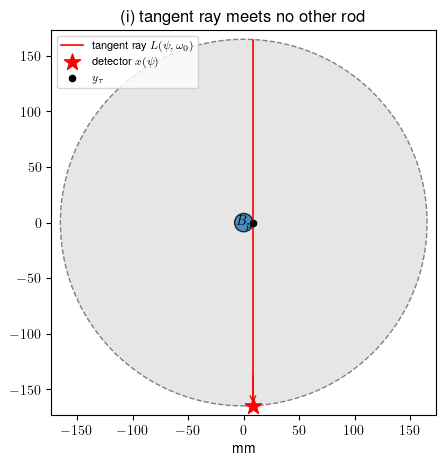

In [9]:
rods_c1 = [(c_p, r, em_p, att_p)]
omega0_c1, eps_c1, L_c1, y_c1 = closest_tangency(x_det, c_p, r, omega=-np.pi/2)
print(f"omega_0 = {omega0_c1:.6f} rad ({np.rad2deg(omega0_c1):.4f} deg), eps_tau = {eps_c1:+.0f}, L = {L_c1:.2f} mm, y_tau = ({y_c1[0]:.3f}, {y_c1[1]:.3f})")
check_simple(x_det, omega0_c1, rods_c1, p=0)
plot_setup(rods_c1, omega0_c1, y_c1, title="(i) tangent ray meets no other rod")

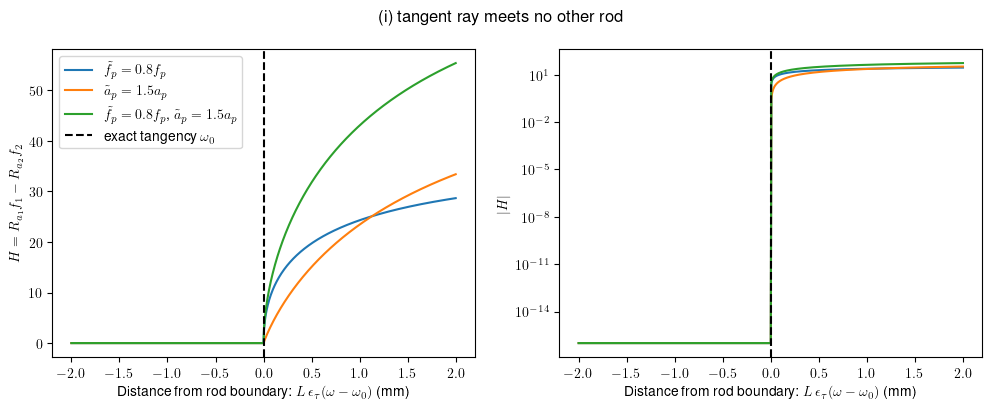

In [10]:
plot_scan(rods_c1, omega0_c1, eps_c1, L_c1, max_depth=2., title="(i) tangent ray meets no other rod")

In [11]:
theory_c1, u_c1, Da_c1 = theory_phis(x_det, omega0_c1, L_c1, y_c1, rods_c1, att_0,
                                     {name: (c["fm2"], c["am2"]) for name, c in comparisons.items()})

max_depth = 2. # Largest penetration depth (mm) on either side, as in the pixel experiment
T_c1 = max_depth / L_c1
nOms = 200
dOmegas = np.linspace(-T_c1, T_c1, nOms) # Even number of points, omega0 itself is excluded
derivative_step_size = 1e-4

results_c1 = run_case(rods_c1, omega0_c1, eps_c1, dOmegas, derivative_step_size)
for name in comparisons:
    Phis_true = theory_c1[name]
    Phis_est = results_c1[name]
    print(f"{name}: Phi_D theory = {Phis_true[0]:10.3f}, estimate = {Phis_est['PhiD'][nOms//2]:10.3f} | ", end="")
    print(f"Phi_N theory = {Phis_true[1]:10.3f}, estimate = {Phis_est['PhiN'][nOms//2]:10.3f}  (closest to omega_0)")

L = 164.79 mm: Da = 1.4007, e^(-Da) = 2.4641e-01, tangential trace u = 0.0000
F_p = f_p - (a_p - a_0) u = 100.0000
data1: Phi_D theory =    256.984, estimate =    230.563 | Phi_N theory =   1762.154, estimate =   1602.040  (closest to omega_0)
data2: Phi_D theory =      0.000, estimate =     64.144 | Phi_N theory =  -4690.144, estimate =  -3515.732  (closest to omega_0)
data3: Phi_D theory =    256.984, estimate =    281.878 | Phi_N theory =  -1989.961, estimate =  -1210.545  (closest to omega_0)


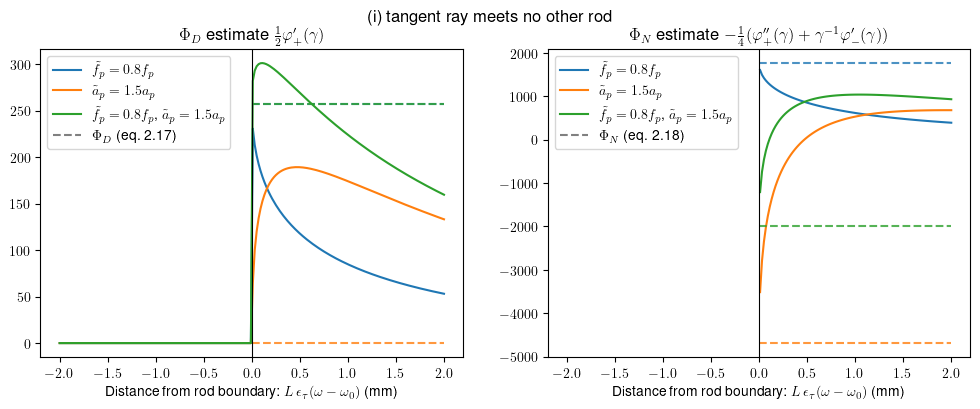

In [12]:
plot_derivs(results_c1, dOmegas, L_c1, theory_c1, title="(i) tangent ray meets no other rod")

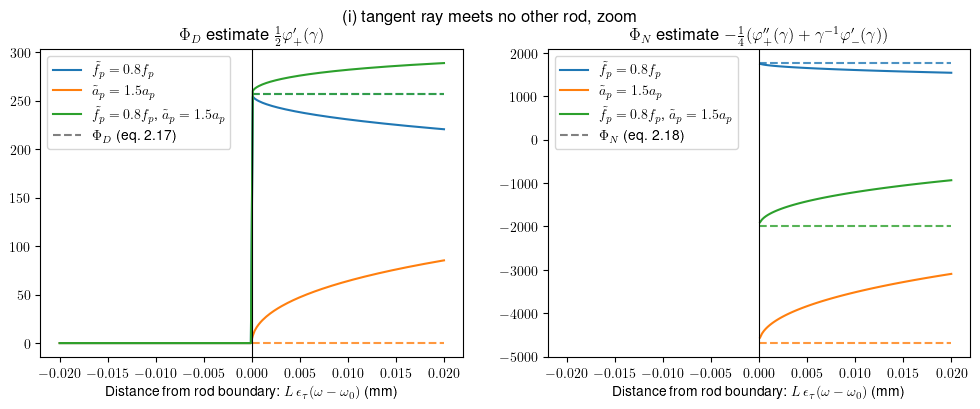

In [13]:
dOmegas_zoom = np.linspace(-0.02, 0.02, nOms) / L_c1
results_c1_zoom = run_case(rods_c1, omega0_c1, eps_c1, dOmegas_zoom, derivative_step_size)
plot_derivs(results_c1_zoom, dOmegas_zoom, L_c1, theory_c1, title="(i) tangent ray meets no other rod, zoom")

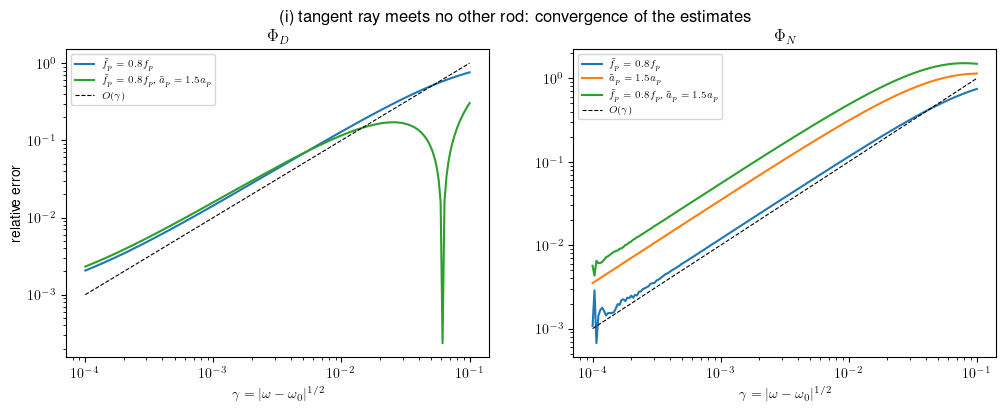

In [14]:
plot_convergence(rods_c1, omega0_c1, eps_c1, theory_c1, title="(i) tangent ray meets no other rod: convergence of the estimates")

# Case (ii): tangent ray passes through a second rod
Second rod at $(r, 3r)$: the tangent line $x = r$ passes through its center, on the far side of $y_\tau$ as seen from the detector, so $u \neq 0$.

omega_0 = -1.570796 rad (-90.0000 deg), eps_tau = +1, L = 164.79 mm, y_tau = (8.250, 0.000)
Rod 1 at (8.25, 24.75): |rho_q| - r = -8.250 mm


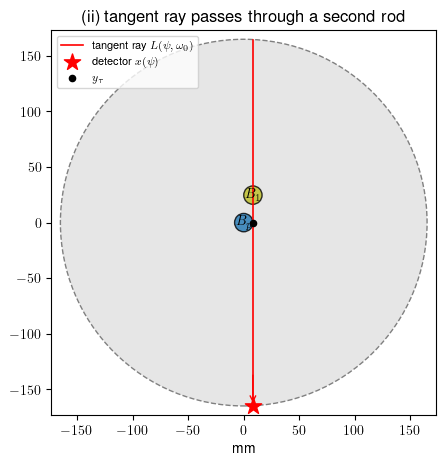

In [15]:
rods_c2 = [(c_p, r, em_p, att_p), (c_q, r, em_p, att_p)]
omega0_c2, eps_c2, L_c2, y_c2 = closest_tangency(x_det, c_p, r, omega=-np.pi/2)
print(f"omega_0 = {omega0_c2:.6f} rad ({np.rad2deg(omega0_c2):.4f} deg), eps_tau = {eps_c2:+.0f}, L = {L_c2:.2f} mm, y_tau = ({y_c2[0]:.3f}, {y_c2[1]:.3f})")
check_simple(x_det, omega0_c2, rods_c2, p=0)
plot_setup(rods_c2, omega0_c2, y_c2, title="(ii) tangent ray passes through a second rod")

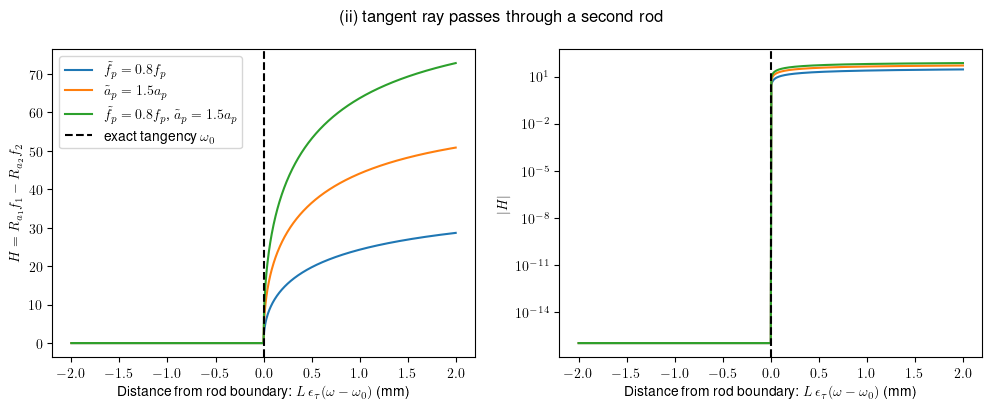

In [16]:
plot_scan(rods_c2, omega0_c2, eps_c2, L_c2, max_depth=2., title="(ii) tangent ray passes through a second rod")

In [17]:
theory_c2, u_c2, Da_c2 = theory_phis(x_det, omega0_c2, L_c2, y_c2, rods_c2, att_0,
                                     {name: (c["fm2"], c["am2"]) for name, c in comparisons.items()})

max_depth = 2.
T_c2 = max_depth / L_c2
dOmegas = np.linspace(-T_c2, T_c2, nOms)
derivative_step_size = 1e-4

results_c2 = run_case(rods_c2, omega0_c2, eps_c2, dOmegas, derivative_step_size)
for name in comparisons:
    Phis_true = theory_c2[name]
    Phis_est = results_c2[name]
    print(f"{name}: Phi_D theory = {Phis_true[0]:10.3f}, estimate = {Phis_est['PhiD'][nOms//2]:10.3f} | ", end="")
    print(f"Phi_N theory = {Phis_true[1]:10.3f}, estimate = {Phis_est['PhiN'][nOms//2]:10.3f}  (closest to omega_0)")

L = 164.79 mm: Da = 1.4007, e^(-Da) = 2.4641e-01, tangential trace u = 559.1921
F_p = f_p - (a_p - a_0) u = 26.4662
data1: Phi_D theory =    256.984, estimate =    230.563 | Phi_N theory =   1762.154, estimate =   1602.040  (closest to omega_0)
data2: Phi_D theory =    502.962, estimate =    442.915 | Phi_N theory =   4043.419, estimate =   3605.463  (closest to omega_0)
data3: Phi_D theory =    759.946, estimate =    660.649 | Phi_N theory =   6743.602, estimate =   5910.650  (closest to omega_0)


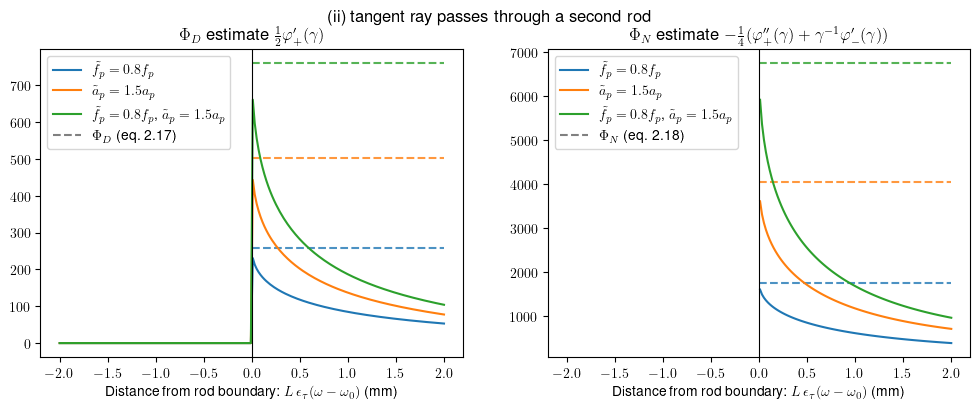

In [18]:
plot_derivs(results_c2, dOmegas, L_c2, theory_c2, title="(ii) tangent ray passes through a second rod")

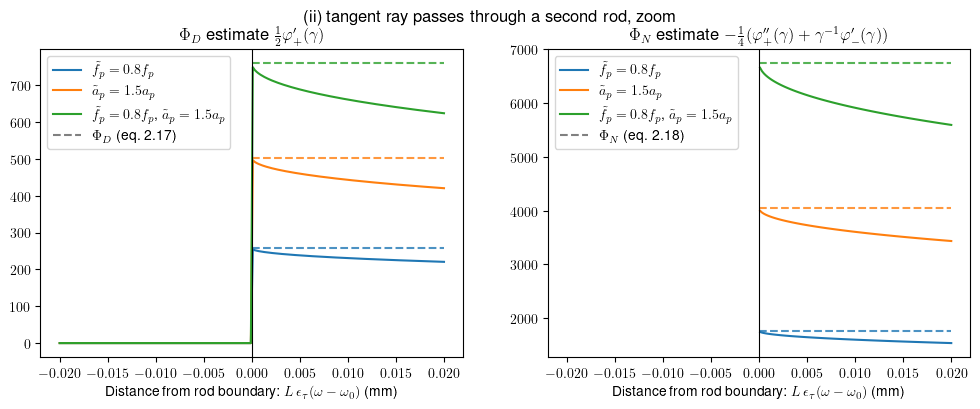

In [19]:
dOmegas_zoom = np.linspace(-0.02, 0.02, nOms) / L_c2
results_c2_zoom = run_case(rods_c2, omega0_c2, eps_c2, dOmegas_zoom, derivative_step_size)
plot_derivs(results_c2_zoom, dOmegas_zoom, L_c2, theory_c2, title="(ii) tangent ray passes through a second rod, zoom")

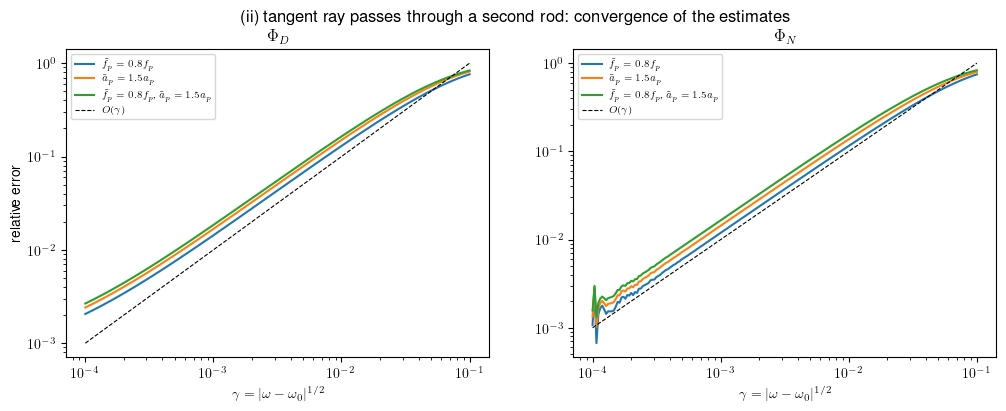

In [20]:
plot_convergence(rods_c2, omega0_c2, eps_c2, theory_c2, title="(ii) tangent ray passes through a second rod: convergence of the estimates")

# Reconstruction from the singular functionals (Remark 4.6)

Apply the estimates to a single dataset $H = R_a f(x(\psi), \cdot)$ and recover the rod coefficients:
$$a_p = a_0 + \frac{\Phi_N[H]}{\sqrt{2rL_\tau}\,\Phi_D[H]}, \qquad f_p = \frac{e^{Da(y_\tau,\theta_\tau)}}{\sqrt{2rL_\tau}}\Phi_D[H] + (a_p - a_0)\,u(y_\tau, \theta_\tau).$$
The last term vanishes at an admissible tangency (case 1). The limits are extrapolated to $\gamma = 0$ by a quadratic fit of the estimates over $\gamma \in [5\cdot 10^{-4}, 1\cdot 10^{-2}]$.

In [21]:
def extrapolated_limits(Hfun, omega0, eps):
    gammas = np.linspace(5e-4, 1e-2, 20)
    PhiD, PhiN = fd_estimates(Hfun, omega0, eps, gammas**2, h=1e-4)
    polyD = np.polyfit(gammas, PhiD, 2)
    polyN = np.polyfit(gammas, PhiN, 2)
    return np.polyval(polyD, 0.), np.polyval(polyN, 0.)

for nm, rods, om0, eps, L, u, Da in [("Case 1", rods_c1, omega0_c1, eps_c1, L_c1, u_c1, Da_c1),
                                     ("Case 2", rods_c2, omega0_c2, eps_c2, L_c2, u_c2, Da_c2)]:
    for label, rr in [("reference", rods), *[(name, perturbed(rods, c)) for name, c in comparisons.items()]]:
        phiD, phiN = extrapolated_limits(data_fun(rr, att_0), om0, eps)

        k = np.sqrt(2*r*L)
        a_rec = att_0 + phiN / (k * phiD)
        f_rec = np.exp(Da) * phiD / k + (a_rec - att_0) * u
        a_re = np.abs(a_rec - rr[0][3]) / np.abs(rr[0][3])
        f_re = np.abs(f_rec - rr[0][2]) / np.abs(rr[0][2])
        print(f"{nm} - {label:9s}: a_p = {a_rec:.5f} (true {rr[0][3]:.6f}), rel err = {a_re:.4f}")
        print(f"{nm} - {label:9s}: f_p = {f_rec:9.3f} (true {rr[0][2]:.3f}), rel err = {f_re:.4f}")

Case 1 - reference: a_p = 0.14009 (true 0.140000), rel err = 0.0007
Case 1 - reference: f_p =    99.930 (true 100.000), rel err = 0.0007
Case 1 - data1    : a_p = 0.14009 (true 0.140000), rel err = 0.0007
Case 1 - data1    : f_p =    79.944 (true 80.000), rel err = 0.0007
Case 1 - data2    : a_p = 0.21022 (true 0.210000), rel err = 0.0010
Case 1 - data2    : f_p =    99.887 (true 100.000), rel err = 0.0011
Case 1 - data3    : a_p = 0.21022 (true 0.210000), rel err = 0.0010
Case 1 - data3    : f_p =    79.910 (true 80.000), rel err = 0.0011
Case 2 - reference: a_p = 0.14009 (true 0.140000), rel err = 0.0007
Case 2 - reference: f_p =   100.033 (true 100.000), rel err = 0.0003
Case 2 - data1    : a_p = 0.14009 (true 0.140000), rel err = 0.0006
Case 2 - data1    : f_p =    80.044 (true 80.000), rel err = 0.0005
Case 2 - data2    : a_p = 0.21023 (true 0.210000), rel err = 0.0011
Case 2 - data2    : f_p =   100.141 (true 100.000), rel err = 0.0014
Case 2 - data3    : a_p = 0.21022 (true 0.21